# Qdrant, hands on

Everything in this notebook uses a throwaway collection of **2-dimensional** vectors,
so you can plot every point and *see* why each query returns what it returns. Real
embeddings are 1024-d and unplottable — the geometry is identical, you just can't look
at it.

We build up to our real `rag_chunks` collection at the end (§11).

**Requires:** `docker compose up -d qdrant`

| Section | |
|---|---|
| 1 | Terminology — Qdrant vs Postgres vs our project |
| 2 | A collection you can see: 2-D toy data |
| 3 | Search, and why cosine means *angle* |
| 4 | Distance metrics disagree — the same data, three answers |
| 5 | Anatomy of a point — and a surprise about what gets stored |
| 6 | Named vectors — why ours has `dense` and `sparse` |
| 7 | Filtering: must / should / must_not |
| 8 | Payload indexes — the thing that dies at scale |
| 9 | HNSW parameters, and which you can change later |
| 10 | Quantization and the memory math |
| 11 | Operational: count, scroll, delete, snapshot |
| 12 | Our real collection |

In [1]:
import json, os, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

from qdrant_client import QdrantClient, models

INK, INK2, SURF = "#0b0b0b", "#52514e", "#fcfcfb"
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "text.color": INK,
    "axes.labelcolor": INK2, "axes.edgecolor": "#d8d7d2",
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#eceae4", "grid.linewidth": 0.8,
})

client = QdrantClient(url="http://localhost:6333", timeout=30)
print("collections:", [c.name for c in client.get_collections().collections])

collections: ['rag_chunks']


## 1. Terminology

Every Qdrant concept has a Postgres counterpart except one.

| Qdrant | Postgres | In our project |
|---|---|---|
| **Collection** | Table | `rag_chunks` |
| **Point** | Row | one chunk of a 10-K |
| **Point ID** | Primary key | UUID5 of `chunk_id` |
| **Vector** | *(no equivalent)* | 1024 floats from BGE-M3 |
| **Payload** | The other columns | `doc_id`, `doc_type`, `text`, … |
| **Payload index** | `CREATE INDEX` | six of them |
| **Filter** | `WHERE` | `doc_type = '10k'` |
| **Distance metric** | *(no equivalent)* | Cosine |
| **Shard** | Partition | 1 (single node) |
| **Segment** | Heap file / segment | internal |
| **Optimizer** | `VACUUM` / autovacuum | internal |
| **Snapshot** | `pg_dump` | not used yet |

**The one genuinely new idea:** Postgres finds rows by *equality or range* — `WHERE
doc_type = '10k'`. Qdrant finds points by **similarity to a vector** — "the 5 points
whose vectors are closest to this one." Everything else is a normal database.

Two more terms with no Postgres analogue, both covered later:

- **Named vector** (§6) — a point can carry several vectors under different names.
- **HNSW** (§9) — the approximate index. Unlike a B-tree, it returns a *probable*
  answer with a recall characteristic you tune.

## 2. A collection you can see

Eight words placed by hand in 2-D. The x-axis is loosely "fruitness", the y-axis
"animalness" — the actual numbers are arbitrary, the *geometry* is the point.

Note `apple_2x`: it points in exactly the same direction as `apple` but is twice as
long. Watch what happens to it under different distance metrics in §4.

In [2]:
TOY = "toy_2d"

POINTS = [
    # id, vector,        payload
    (1, [0.90, 0.10], {"word": "apple",    "kind": "fruit",  "calories": 52}),
    (2, [0.95, 0.20], {"word": "banana",   "kind": "fruit",  "calories": 89}),
    (3, [0.85, 0.15], {"word": "cherry",   "kind": "fruit",  "calories": 50}),
    (4, [1.80, 0.20], {"word": "apple_2x", "kind": "fruit",  "calories": 52}),
    (5, [0.10, 0.95], {"word": "dog",      "kind": "animal", "calories": 0}),
    (6, [0.15, 0.90], {"word": "cat",      "kind": "animal", "calories": 0}),
    (7, [0.05, 0.98], {"word": "wolf",     "kind": "animal", "calories": 0}),
    (8, [0.60, 0.60], {"word": "tomato",   "kind": "fruit",  "calories": 18}),
]

def build(distance: models.Distance) -> None:
    """Recreate the toy collection with a given distance metric."""
    if client.collection_exists(TOY):
        client.delete_collection(TOY)
    client.create_collection(
        collection_name=TOY,
        vectors_config=models.VectorParams(size=2, distance=distance),
    )
    client.upsert(TOY, points=[
        models.PointStruct(id=i, vector=v, payload=p) for i, v, p in POINTS
    ], wait=True)

build(models.Distance.COSINE)
print(f"{client.count(TOY).count} points, distance=COSINE")

8 points, distance=COSINE


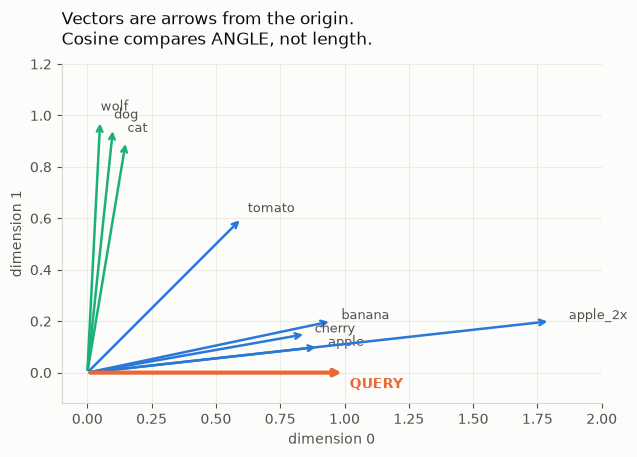

In [3]:
QUERY = [1.0, 0.0]          # "pure fruit direction"

fig, ax = plt.subplots(figsize=(6.5, 6))
for i, v, p in POINTS:
    col = C1 if p["kind"] == "fruit" else C3
    ax.annotate("", xy=v, xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", color=col, lw=1.8))
    ax.text(v[0]*1.04, v[1]*1.04, p["word"], color=INK2, fontsize=9)
ax.annotate("", xy=QUERY, xytext=(0, 0),
            arrowprops=dict(arrowstyle="->", color=C2, lw=3))
ax.text(QUERY[0]*1.02, -0.06, "QUERY", color=C2, fontsize=10, weight="bold")

ax.set_xlim(-0.1, 2.0); ax.set_ylim(-0.12, 1.2)
ax.set_xlabel("dimension 0"); ax.set_ylabel("dimension 1")
ax.set_title("Vectors are arrows from the origin.\nCosine compares ANGLE, not length.",
             fontsize=12, color=INK, pad=14, loc="left")
ax.grid(True, zorder=0); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

Drawing them as arrows from the origin is deliberate: **cosine similarity is the
angle between two arrows.** Length is divided out entirely. That is why `apple` and
`apple_2x` — same direction, double length — are *identical* to a cosine search.

## 3. Search

`query_points` takes a query vector and returns the nearest points.

In [4]:
res = client.query_points(TOY, query=QUERY, limit=8, with_payload=True).points
pd.DataFrame([{"rank": i, "id": p.id, "word": p.payload["word"],
               "kind": p.payload["kind"], "score": round(p.score, 4)}
              for i, p in enumerate(res, 1)]).set_index("rank")

,id,word,kind,score
rank,,,,
1,4,apple_2x,fruit,0.9939
2,1,apple,fruit,0.9939
3,3,cherry,fruit,0.9848
4,2,banana,fruit,0.9785
5,8,tomato,fruit,0.7071
6,6,cat,animal,0.1644
7,5,dog,animal,0.1047
8,7,wolf,animal,0.0510


Read the scores against the picture:

- **`apple` and `apple_2x` score identically** (both ~0.994). Same angle. Cosine cannot
  distinguish them — magnitude is normalised away.
- The fruits cluster at ~0.98–0.99; the animals sit at ~0.10–0.15.
- `tomato`, drawn at 45°, lands at ~0.707 — which is exactly `cos(45°)`. The metric is
  doing plain trigonometry.

**Score direction matters and differs by metric.** For `COSINE` and `DOT`, higher is
more similar. For `EUCLID` and `MANHATTAN`, Qdrant returns a *distance*, so **lower is
closer** — and the ordering flips. Sort the wrong way and you retrieve the least
relevant documents while everything appears to work.

## 4. The same data, three metrics, three answers

In [5]:
rows = []
for dist in [models.Distance.COSINE, models.Distance.DOT, models.Distance.EUCLID]:
    build(dist)
    r = client.query_points(TOY, query=QUERY, limit=3, with_payload=True).points
    rows.append({
        "metric": dist.value,
        "better": "higher" if dist != models.Distance.EUCLID else "LOWER",
        "top 3": " > ".join(p.payload["word"] for p in r),
        "top score": round(r[0].score, 3),
    })
pd.DataFrame(rows).set_index("metric")

,better,top 3,top score
metric,,,
Cosine,higher,apple > apple_2x > cherry,0.994
Dot,higher,apple_2x > banana > apple,1.800
Euclid,LOWER,apple > banana > cherry,0.141


| Metric | What it measures | `apple_2x` |
|---|---|---|
| **Cosine** | Angle only; length normalised away | ties with `apple` |
| **Dot** | Angle **and** magnitude | **wins** — it's longer |
| **Euclid** | Straight-line distance | **loses** — it's far from the query point |

Same eight points, same query, three different winners.

**Which should you use?** If your vectors are unit-normalised, cosine and dot are
equivalent, and dot is marginally cheaper. If they are *not* normalised, dot rewards
long vectors — and vector length correlates with text length, so you would
systematically favour longer chunks regardless of relevance.

That is why [scripts/embed_server.py](../scripts/embed_server.py) normalises on the
server and our collection uses `COSINE`: two independent safeguards against the same
failure. This is also why `verify_contract` checks the L2 norm is 1.0 — an
unnormalised model silently turns "most relevant" into "longest".

## 5. Anatomy of a point

In [6]:
build(models.Distance.COSINE)
pt = client.retrieve(TOY, ids=[1], with_vectors=True, with_payload=True)[0]
print("id      ", pt.id)
print("vector  ", pt.vector)
print("payload ", pt.payload)

id       1
vector   [0.9938837, 0.11043153]
payload  {'word': 'apple', 'kind': 'fruit', 'calories': 52}


### Wait — that is not the vector we stored

We inserted `apple` as `[0.90, 0.10]`. It came back as `[0.9938837, 0.11043153]`.

**Qdrant normalised it on write, because the collection uses `COSINE`.** Check the
arithmetic: `[0.9, 0.1]` has length `sqrt(0.81 + 0.01) = 0.9055`, and
`0.9 / 0.9055 = 0.9939`. Exactly what came back.

In [7]:
orig = np.array([0.90, 0.10])
back = np.array(pt.vector)
print(f"we sent      {orig}   norm {np.linalg.norm(orig):.4f}")
print(f"we got back  {back.round(6)}   norm {np.linalg.norm(back):.4f}")
print(f"sent / norm  {(orig / np.linalg.norm(orig)).round(6)}   <- matches")

# apple and apple_2x were stored as literally the same vector.
a  = np.array(client.retrieve(TOY, ids=[1], with_vectors=True)[0].vector)
a2 = np.array(client.retrieve(TOY, ids=[4], with_vectors=True)[0].vector)
print("apple    stored as", a.round(6))
print("apple_2x stored as", a2.round(6))
print("identical?", np.allclose(a, a2))

we sent      [0.9 0.1]   norm 0.9055
we got back  [0.993884 0.110432]   norm 1.0000
sent / norm  [0.993884 0.110432]   <- matches
apple    stored as [0.993884 0.110432]
apple_2x stored as [0.993884 0.110432]
identical? True


Two consequences that matter in production:

**1. You cannot get your original vector back from a COSINE collection.** It is gone —
overwritten by its normalised form. If you need the raw vector later (for a different
metric, for debugging, for a model migration), store it in the payload or keep it
outside Qdrant.

**2. `apple` and `apple_2x` are now literally the same point-vector.** Section 4's
result was not "cosine chose to ignore magnitude at query time" — the magnitude was
*discarded at write time*. There is nothing left to distinguish them by.

This is also a small instance of [L14](../docs/LESSONS.md): the stored state is not
the requested state, and the only way to find out was to read it back and measure.

## 5b. The parts of a point

Three parts:

- **`id`** — integer or UUID **only**. Not an arbitrary string. Our `chunk_id` is a
  hex digest, so [qdrant_store.py](../rag/index/qdrant_store.py) wraps it in a
  deterministic `uuid5`. Deterministic matters: re-ingesting the same chunk must
  *overwrite*, not duplicate.
- **`vector`** — what gets searched.
- **`payload`** — arbitrary JSON. Filterable, returnable, and *not* searched by
  similarity.

**Vectors are hidden by default.** `with_vectors=True` above is required — the API
omits them otherwise, which is why the dashboard shows only payload. 1024 floats per
point would make every response enormous, and you cannot learn anything by reading
them anyway.

## 6. Named vectors

A point can hold several vectors under different names. Our real collection declares
two.

In [8]:
NAMED = "toy_named"
if client.collection_exists(NAMED):
    client.delete_collection(NAMED)

client.create_collection(
    collection_name=NAMED,
    vectors_config={                       # dict, not a bare VectorParams
        "dense": models.VectorParams(size=2, distance=models.Distance.COSINE),
    },
    sparse_vectors_config={
        "sparse": models.SparseVectorParams(modifier=models.Modifier.IDF),
    },
)
client.upsert(NAMED, points=[
    models.PointStruct(id=1, vector={"dense": [0.9, 0.1]}, payload={"word": "apple"}),
], wait=True)

print("named-vector point:")
print(" ", client.retrieve(NAMED, ids=[1], with_vectors=True)[0].vector)
print("\nsearching a named-vector collection REQUIRES `using=`:")
try:
    client.query_points(NAMED, query=[1.0, 0.0], limit=1)
except Exception as e:
    print("  without using= ->", type(e).__name__)
print("  with using='dense' ->",
      client.query_points(NAMED, query=[1.0, 0.0], using="dense", limit=1).points[0].id)

named-vector point:
  {'dense': [0.9938837, 0.11043153]}

searching a named-vector collection REQUIRES `using=`:
  without using= -> UnexpectedResponse
  with using='dense' -> 1


Two things to take from that:

**The vector comes back as `{'dense': [...]}`**, not a flat list. That extra nesting
is what you were seeing in the dashboard.

**The set of named vectors is fixed at creation and cannot be changed.** That is why
Step 0.5 declared `sparse` now even though it stays empty until Phase 5 — otherwise
adding hybrid search later means creating a new collection and re-embedding all
71,248 chunks. An unpopulated named vector costs nothing.

`modifier=IDF` tells Qdrant to apply inverse-document-frequency weighting to the
sparse vectors — that's what makes them behave like BM25 when we populate them.

## 7. Filtering

Qdrant's filter language is three clauses, matching boolean logic:

| Clause | SQL | Meaning |
|---|---|---|
| `must` | `AND` | all conditions hold |
| `should` | `OR` | at least one holds |
| `must_not` | `NOT` | none hold |

In [9]:
def find(flt, label):
    r = client.query_points(TOY, query=QUERY, limit=8, query_filter=flt,
                            with_payload=True).points
    return {"filter": label, "n": len(r),
            "words": ", ".join(p.payload["word"] for p in r)}

F = models.FieldCondition
rows = [
    find(None, "no filter"),
    find(models.Filter(must=[F(key="kind", match=models.MatchValue(value="fruit"))]),
         "must: kind=fruit"),
    find(models.Filter(must_not=[F(key="kind", match=models.MatchValue(value="fruit"))]),
         "must_not: kind=fruit"),
    find(models.Filter(must=[F(key="calories", range=models.Range(gte=50))]),
         "must: calories >= 50"),
    find(models.Filter(should=[F(key="word", match=models.MatchValue(value="dog")),
                               F(key="word", match=models.MatchValue(value="apple"))]),
         "should: dog OR apple"),
    find(models.Filter(
        must=[F(key="kind", match=models.MatchValue(value="fruit"))],
        must_not=[F(key="word", match=models.MatchValue(value="apple_2x"))]),
         "fruit AND NOT apple_2x"),
]
pd.DataFrame(rows).set_index("filter")

,n,words
filter,,
no filter,8,"apple, apple_2x, cherry, banana, tomato, cat, ..."
must: kind=fruit,5,"apple, apple_2x, cherry, banana, tomato"
must_not: kind=fruit,3,"cat, dog, wolf"
must: calories >= 50,4,"apple, apple_2x, cherry, banana"
should: dog OR apple,2,"apple, dog"
fruit AND NOT apple_2x,4,"apple, cherry, banana, tomato"


### The critical part: the filter runs *inside* the search

Notice `must: calories >= 50` returned **3** results, not 8-minus-something taken from
a top-8 list. Qdrant applied the filter during retrieval and then found the nearest
*matching* points.

The alternative — search first, drop non-matching after — is **post-filtering**, and it
breaks in two ways:

1. You ask for 10 and get 2, because 8 of the top 10 failed the filter.
2. **It is not an access control.** If the filter is `tenant_id = X`, post-filtering
   means the engine looked at other tenants' vectors and you are relying on
   application code to discard them. That is Phase 12's central problem.

Our [`QdrantStore.search`](../rag/index/qdrant_store.py) passes `query_filter=`, so
filtering happens server-side inside the search. Never filter the returned list.

## 8. Payload indexes — the thing that quietly dies at scale

Qdrant will filter on any payload field. **Without an index it does so by scanning.**

In [10]:
before = client.get_collection(TOY).payload_schema
print("indexed fields before:", sorted(before.keys()) or "none")

client.create_payload_index(TOY, field_name="kind",
                            field_schema=models.PayloadSchemaType.KEYWORD)
client.create_payload_index(TOY, field_name="calories",
                            field_schema=models.PayloadSchemaType.INTEGER)

after = client.get_collection(TOY).payload_schema
pd.DataFrame([{"field": k, "type": str(v.data_type), "points": v.points}
              for k, v in after.items()]).set_index("field")

indexed fields before: none


,type,points
field,,
calories,integer,8
kind,keyword,8


With 8 points a scan is instant, which is exactly what makes this dangerous: **it
passes every test you can run in development.**

There is a second, less obvious reason indexes matter. Qdrant uses the index to
**estimate how many points a filter matches**, and that estimate decides its strategy:

| Filter matches | Strategy chosen |
|---|---|
| Few points | Brute-force the matching subset — exact and fast |
| Many points | Filtered HNSW traversal |

Without an index it cannot estimate, so it cannot choose. And a filtered graph
traversal that goes wrong doesn't error — **the path to the answer may run through
excluded nodes, the walk stalls in a disconnected region, and recall collapses
silently.** That combination (no error, wrong answers, only at scale) is why our real
collection declares six payload indexes at creation time.

## 9. HNSW parameters

In [11]:
cfg = client.get_collection(TOY).config
h = cfg.hnsw_config
pd.DataFrame([
    {"param": "m", "value": h.m,
     "meaning": "links per node", "changeable": "rebuild"},
    {"param": "ef_construct", "value": h.ef_construct,
     "meaning": "build-time beam width", "changeable": "rebuild"},
    {"param": "full_scan_threshold", "value": h.full_scan_threshold,
     "meaning": "below this many points, skip HNSW entirely", "changeable": "yes"},
    {"param": "ef (search)", "value": "per-query",
     "meaning": "query-time beam width", "changeable": "EVERY QUERY"},
]).set_index("param")

,value,meaning,changeable
param,,,
m,16,links per node,rebuild
ef_construct,100,build-time beam width,rebuild
full_scan_threshold,10000,"below this many points, skip HNSW entirely",yes
ef (search),per-query,query-time beam width,EVERY QUERY


In [12]:
# ef_search is passed per query — the only knob you can turn without a rebuild.
for ef in [4, 16, 128]:
    r = client.query_points(TOY, query=QUERY, limit=3,
                            search_params=models.SearchParams(hnsw_ef=ef)).points
    print(f"ef_search={ef:>4}  ->  ids {[p.id for p in r]}")

ef_search=   4  ->  ids [1, 4, 3]
ef_search=  16  ->  ids [1, 4, 3]
ef_search= 128  ->  ids [1, 4, 3]


At 8 points every `ef` gives the same answer — note `full_scan_threshold` is 10000,
so Qdrant isn't even using HNSW here; it brute-forces. **Small collections don't
exercise the index at all**, which is worth knowing before you draw conclusions from a
dev environment.

| Parameter | Trade | When you can change it |
|---|---|---|
| `m` | Recall ↑, memory `n × 2m × 4` bytes, build time ↑ | Rebuild |
| `ef_construct` | Graph quality ↑, build time ↑ | Rebuild |
| **`ef_search`** | **Recall ↑, latency ↑** | **Every query** |

`ef_search` being tunable live is why it's the knob you reach for at 3am: recall too
low, raise it; p95 too high, lower it. No reindex, no deploy. Phase 5 measures that
curve on real data.

## 10. Quantization and the memory math

Quantization compresses each vector component. It cuts memory *and* speeds up search,
because HNSW is bound by memory latency rather than arithmetic.

In [13]:
n, d = 71_248, 1024        # our real corpus
rows = []
for name, bytes_per in [("float32 (default)", 4), ("int8 (scalar)", 1), ("binary", 1/8)]:
    vec = n * d * bytes_per
    rows.append({"mode": name, "bytes/component": bytes_per,
                 "our corpus": f"{vec/1e6:,.0f} MB",
                 "at 100M chunks": f"{100e6 * d * bytes_per / 1e9:,.0f} GB"})
graph = n * 2 * 16 * 4
rows.append({"mode": "HNSW links (m=16)", "bytes/component": "—",
             "our corpus": f"{graph/1e6:,.0f} MB",
             "at 100M chunks": f"{100e6 * 2 * 16 * 4 / 1e9:,.0f} GB"})
pd.DataFrame(rows).set_index("mode")

,bytes/component,our corpus,at 100M chunks
mode,,,
float32 (default),4,292 MB,410 GB
int8 (scalar),1,73 MB,102 GB
binary,0.125,9 MB,13 GB
HNSW links (m=16),—,9 MB,13 GB


In [14]:
# Enabling scalar quantization on an existing collection (no re-upsert needed).
client.update_collection(
    collection_name=TOY,
    quantization_config=models.ScalarQuantization(
        scalar=models.ScalarQuantizationConfig(
            type=models.ScalarType.INT8,
            quantile=0.99,      # clip outliers before scaling
            always_ram=True,    # keep the compressed vectors in RAM
        )
    ),
)
q = client.get_collection(TOY).config.quantization_config
print("quantization now:", q)

quantization now: scalar=ScalarQuantizationConfig(type=<ScalarType.INT8: 'int8'>, quantile=0.99, always_ram=True, memory=None)


### The number that changes an architecture

At 100M chunks, float32 needs **410 GB** — you must shard, and you now own routing,
fan-out, partial failure and rebalancing. Binary needs **12.8 GB** plus 12.8 GB of
graph, which fits in RAM on one large machine.

**Quantization is not a memory optimisation. It is the decision that determines
whether you operate a distributed system.**

The accuracy cost is recovered by **re-scoring**: search the compressed index for the
top ~200, then re-rank those few with full-precision vectors. You pay 32× less memory
for the search and full precision only where it matters.

At *our* scale none of this is needed — 71k × 1024 × 4 bytes is 292 MB. We're learning
the mechanism, not solving a problem.

## 11. Operational commands

In [15]:
print("count all                    :", client.count(TOY).count)
print("count with filter            :", client.count(TOY, count_filter=models.Filter(
    must=[F(key="kind", match=models.MatchValue(value="fruit"))])).count)

pts, next_off = client.scroll(TOY, limit=3, with_payload=["word"])
print("scroll page 1                :", [p.payload["word"] for p in pts])
print("next offset (cursor)         :", next_off)

client.delete(TOY, points_selector=models.PointIdsList(points=[4]), wait=True)
print("after deleting id=4          :", client.count(TOY).count)

client.delete(TOY, points_selector=models.FilterSelector(filter=models.Filter(
    must=[F(key="kind", match=models.MatchValue(value="animal"))])), wait=True)
print("after deleting all animals   :", client.count(TOY).count)

count all                    : 8
count with filter            : 5
scroll page 1                : ['apple', 'banana', 'cherry']
next offset (cursor)         : 4
after deleting id=4          : 7
after deleting all animals   : 4


**`scroll` vs `query_points`.** `scroll` paginates through *all* points with no
similarity involved — the equivalent of `SELECT ... LIMIT/OFFSET`. Use it to walk a
collection; use `query_points` to search it.

**Delete by filter** is how Phase 11 makes document deletion propagate: one call
removes every chunk of a document. Phase 12 needs it because a document that remains
retrievable after deletion is a compliance breach, not untidiness.

**A caveat worth knowing:** HNSW has no clean delete. Removing a node would strand the
links pointing at it, so Qdrant *tombstones* instead and the graph degrades until the
optimizer rebuilds affected segments. Deleting a large fraction of a collection
therefore leaves it slower until that happens.

## 12. Our real collection

Everything above, applied to `rag_chunks`.

In [16]:
from rag.index.qdrant_store import QdrantStore, INDEXED_PAYLOAD, DENSE

store = QdrantStore()
if not client.collection_exists(store.collection):
    print("rag_chunks does not exist yet — run: python -m rag.cli index build --limit 3 --recreate")
else:
    info = client.get_collection(store.collection)
    print("points          :", info.points_count)
    print("status          :", info.status)
    print("named vectors   :", list((info.config.params.vectors or {}).keys()))
    print("sparse vectors  :", list((info.config.params.sparse_vectors or {}).keys()))
    print("hnsw m          :", info.config.hnsw_config.m)
    print("payload indexes :", sorted((info.payload_schema or {}).keys()))

points          : 3437
status          : green
named vectors   : ['dense']
sparse vectors  : ['sparse']
hnsw m          : 16
payload indexes : ['doc_id', 'doc_type', 'effective_date', 'embed_model_version', 'sensitivity', 'tenant_id']


In [17]:
# Tidy up the throwaway collections. rag_chunks is left alone.
for name in (TOY, NAMED):
    if client.collection_exists(name):
        client.delete_collection(name)
print("remaining:", [c.name for c in client.get_collections().collections])

remaining: ['rag_chunks']


## Recap — the eight things worth remembering

1. **Collection = table, point = row, payload = the other columns.** Only "search by
   vector similarity" is genuinely new.
2. **Cosine compares angle; length is normalised away.** Dot rewards magnitude, and
   magnitude correlates with text length — so unnormalised vectors + dot product
   silently favours longer chunks.
3. **Euclid and Manhattan return distance: lower is better.** The sort order flips.
4. **Point IDs must be integers or UUIDs**, and should be deterministic so re-ingest
   overwrites instead of duplicating.
5. **Vectors are hidden unless you ask** (`with_vectors=True`).
6. **The set of named vectors is immutable after creation** — declare `sparse` now or
   re-embed everything later.
7. **Filter inside the search, never on the results.** Post-filtering returns short
   result sets and is not an access control.
8. **Payload indexes are not just speed.** They enable the cardinality estimate that
   picks a search strategy — and a wrong choice degrades recall *silently*, only at
   scale.

Next: [notebook 03](03_pipeline_walkthrough.ipynb) puts these together on the real
corpus, and Phase 5 measures the `ef_search` recall/latency curve.